In [170]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import axes3d
from scipy.spatial.distance import cdist

plt.rcParams["animation.html"] = "jshtml"

In [2]:
def brownian_motion(num_processes, num_points, time):
    """
    This function simulates several independent Brownian Motion processes
    over a given time length sampled over a given number of points 

    Args:
        num_processes (int): number of independent Brownian motion processes to be simulated
        num_points (int): number of points to sample the processes over
        time (float): total length of time to simulate the Brownian motions over

    Returns:
        (arr of floats of size num_points x num_processes): points for each Brownian Motion process at each specified points
        (arr of floats of size num_points): time steps for each point the processes are evaluated at
    """

    B = np.zeros((num_points, num_processes))
    dt = time / (num_points - 1)
    time_steps = np.linspace(0, time, num_points)

    for i in range(num_points - 1):
        rand_increment = np.random.normal(0, np.sqrt(dt), num_processes)
        B[i+1] = B[i] + rand_increment

    return B, time_steps

def ito_process(drift, diffusion):
    """
    This function returns the Ito process with a given drift and diffusion component as a function, which may
    later be evaluated for a given simulation of Brownian motion.

    Args:
        drift (function): deterministic term of Ito process that depends on time and the current value
        diffusion (function): non-deterministic term of Ito process that depends on time and the current value

    Returns:
        (function): function that evaluates the associated Ito integral for using Euler's method
    """

    def ito_integral(num_processes, num_points, time):
        B, time_steps = brownian_motion(num_processes, num_points, time)

        for i in range(len(time_steps) - 1):
            break
            
        return 0
    
    return ito_integral

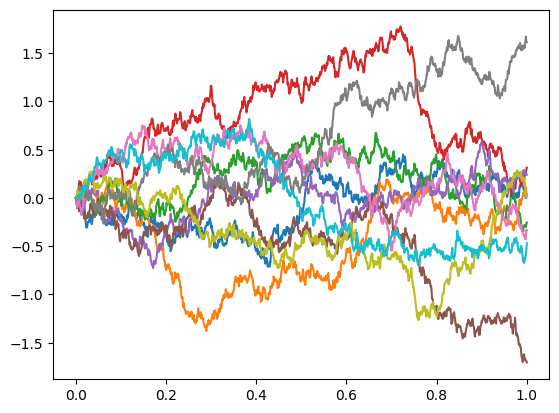

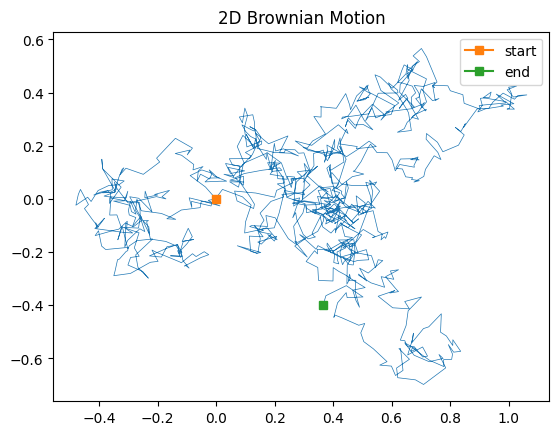

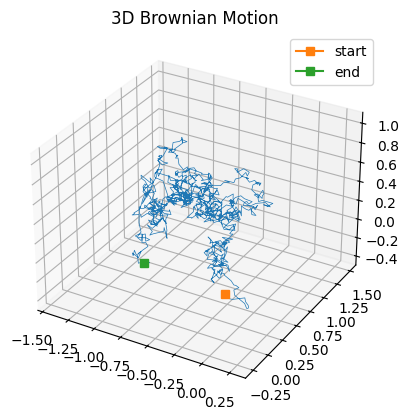

In [3]:
B, t = brownian_motion(10, 1000, 1)
for i in range(10):
    plt.plot(t, B[:, i])
plt.show()

B2, t2 = brownian_motion(3, 1000, 1)
plt.figure()
plt.plot(B2[:, 0], B2[:, 1], linewidth=0.5)
plt.plot(B2[0, 0], B2[0, 1], marker='s', label='start')
plt.plot(B2[-1, 0], B2[-1, 1], marker='s', label='end')
plt.title('2D Brownian Motion')
plt.legend()
plt.show()

B3, t3 = brownian_motion(3, 1000, 1)
plt.figure()
ax = plt.axes(projection='3d')
ax.plot3D(B3[:, 0], B3[:, 1], B3[:, 2], linewidth=0.5)
ax.plot3D(B3[0, 0], B3[0, 1], B3[0, 2], marker='s', label='start')
ax.plot3D(B3[-1, 0], B3[-1, 1], B3[-1, 2], marker='s', label='end')
plt.title('3D Brownian Motion')
plt.legend()
plt.show()

In [4]:
def diffusion_limited_aggregation(num_particles, radius, width, height, time):
    """
    Simulates 2D Diffusion Limited Aggregation for a given number and size of particles as 
    well as the size of the box containing them

    Args:
        num_particles (int): number of particles starting in the box
        radius (float): size of each particle generated
        width (float): width of the containing box
        height (float): height of the containing box

    Returns:
        particles (2D array of floats): positions of the particles at the end of the simulation
        cluster (1D array of ints): times that each particle was added to the cluster, if at all
    """

    particles = np.stack((np.random.uniform(-width/2, width/2, num_particles),
                         np.random.uniform(-height/2, height/2, num_particles)),
                         axis=1)
    particles[0] = [0, 0]
    
    # Keep track of particles that are in the cluster: 
    #   0 if they are free
    #   t > 0 if they are in the cluster (where t is the time they were added)
    cluster = np.zeros(num_particles)
    cluster[0] = 1

    for t in range(2, time+2):
        # Move free particles
        dla_step(particles, cluster, width, height)

        # Check if free particles are close enough to cluster particles
        cluster = check_cluster(particles, cluster, radius, t)

    return particles, cluster

def dla_step(particles, cluster, width, height):
    """
    Simulates one step of a 2D Diffusion Limited Aggression process. Moves each free particle, 
    checks if they are within the boundary conditions, and moves them to the boundary if they
    go outside of it.

    Args:
        particles (2D array of floats): positions of every particle in the process
        cluster (1D array of ints): times that each particle was added to the cluster, if at all
        width (float): width of the boundary containing box
        height (float): height of the boundary containing box

    Returns:
        particles (2D array of floats): updated particles array with random movement of free moving particles
    """
    free = (cluster == 0)

    # Move each free particle
    particles[free] += np.random.uniform(-5, 5, (len(particles[free]), 2))

    # Check particles around boundary condition
    np.clip(particles[:, 0], -width/2, width/2, out = particles[:, 0])
    np.clip(particles[:, 1], -height/2, height/2, out = particles[:, 1])

    return particles

def check_cluster(particles, cluster, radius, time):
    """
    Checks which free particles intersect with cluster particles and adds them to the cluster.

    Args:
        particles (2D array of floats): positions of every particle in the process
        cluster (1D array of ints): times that each particle was added to the cluster, if at all
        radius (float): size of radius of each given particle

    Returns:
        cluster (1D array of ints): updated array of cluster times
    """
    cluster_particles = particles[cluster > 0]
    free_particles = particles[cluster == 0]

    # Compute array of distances between cluster and free particles
    dist = cdist(cluster_particles, free_particles)

    # Update cluster array if distance between any pair of 
    # cluster and free particles is less than 2 * radius
    free_index = np.where(cluster == 0)[0]
    intersect = (dist < 2 * radius).any(axis = 0)
    cluster[free_index[intersect]] = time

    return cluster

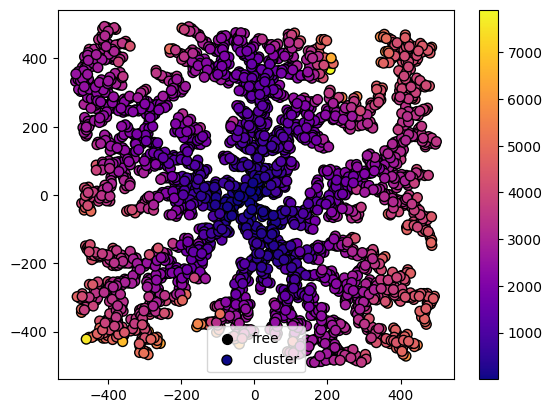

In [251]:
HEIGHT = 1000
WIDTH = 1000
PARTICLES = 3000
RADIUS = 5
TIME = 10000

particles, cluster = diffusion_limited_aggregation(PARTICLES, RADIUS, HEIGHT, WIDTH, TIME)
free_p = particles[cluster == 0]
cluster_p = particles[cluster > 0]

plt.scatter(free_p[:, 0], free_p[:, 1], c='black', s=10*RADIUS, label='free', edgecolors='black')
plt.scatter(cluster_p[:, 0], cluster_p[:, 1], c=cluster, cmap='plasma', s=10*RADIUS, label='cluster', edgecolors='black')
plt.colorbar()
plt.legend()
plt.show()

In [ ]:
# NOTE: if you set the value of tstep too low, then the animation
#       takes too many bytes and is cut off slightly early

tstep = 50      # Number of timesteps between each frame

fig, ax = plt.subplots()
scat = ax.scatter(cluster_p[0, 0], cluster_p[0, 1], edgecolors='black')
ax.set(xlim=[-WIDTH/2, WIDTH/2], ylim = [-HEIGHT/2, HEIGHT/2])

def update(frame):
    cluster_x = particles[(0 < cluster) & (cluster < frame*tstep)][:, 0]
    cluster_y = particles[(0 < cluster) & (cluster < frame*tstep)][:, 1]

    # Update scatter plot
    data = np.stack([cluster_x, cluster_y], axis=1)
    scat.set_offsets(data)

    return scat

ani = animation.FuncAnimation(fig=fig, func=update, frames=int(np.max(cluster))//tstep, interval=45)
ani

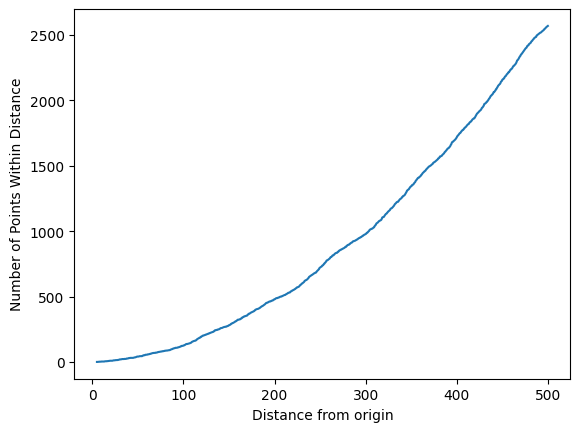

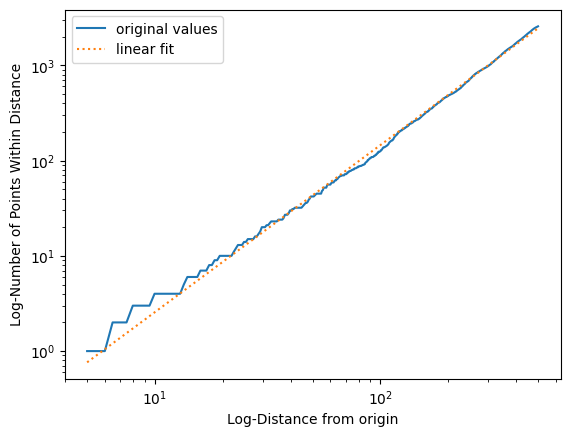

Log-Log Slope: 1.753448192697624
Log-Log Intercept -3.0935232209913517


In [7]:
# FRACTAL DIMENSION COMPUTATION

norms = np.linalg.norm(cluster_p, axis=1)
distances = np.linspace(RADIUS, min(WIDTH, HEIGHT) / 2, 1000)
num_distances = np.zeros(1000)
for i in range(len(distances)):
    num_distances[i] = len(cluster_p[norms < distances[i]])

plt.plot(distances, num_distances)
plt.xlabel('Distance from origin')
plt.ylabel('Number of Points Within Distance')
plt.show()

np_m, np_b = np.linalg.lstsq(np.stack((np.log(distances), np.ones(len(distances))), axis=1), np.log(num_distances), rcond=None)[0]

plt.loglog(distances, num_distances, label='original values')
plt.loglog(distances, np.exp(np_m * np.log(distances) + np_b), linestyle='dotted', label='linear fit')
plt.xlabel('Log-Distance from origin')
plt.ylabel('Log-Number of Points Within Distance')
plt.legend()
plt.show()

print("Log-Log Slope:", np_m)
print("Log-Log Intercept", np_b)

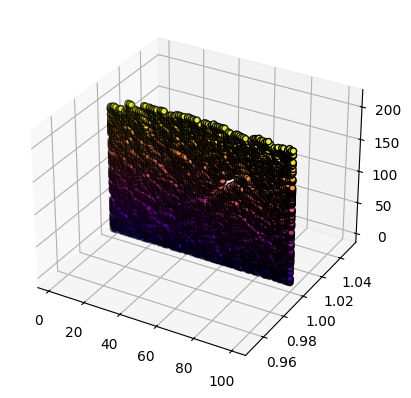

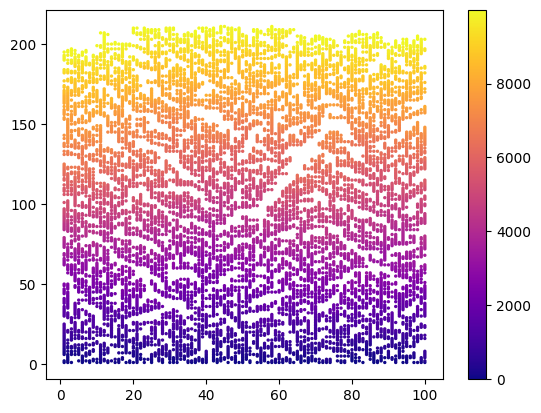

In [245]:
def ballistic_deposition(length, width, time):
    """
    Simulates (2+1)D Ballistic Deposition on a 2D lattice

    Args:
        length (int): number of lattice points in one dimension
        width (int): number of lattice points in one dimension
        time (int): number of steps to simulate ballistic deposition for

    Returns:
        particles (array of 3-tuples): positions and heights of particles added to surface at each time step
    """

    heights = np.zeros((length+2, width+2))
    particles = np.zeros((time, 3))

    x_vals = np.random.randint(1, length+1, time)
    y_vals = np.random.randint(1, width+1, time)

    for t in range(time):
        h = max_adjacent(heights, (x_vals[t], y_vals[t]))
        heights[x_vals[t], y_vals[t]] = h
        particles[t] = x_vals[t], y_vals[t], h

    return particles

def max_adjacent(heights, position):
    """
    For a given position on the lattice and the array of heights on the lattice, checks and returns
    the largest height among all adjacent neighbors and the current position + 1

    Args:
        heights (2D array of ints): contains the height of the surface at every position
        position (int, int): 2-tuple of ints that determine a position on the lattice

    Returns:
        (int) maximum height among the current position's height + 1 and its adjacent neighbors
    """
    x = position[0]
    y = position[1]

    return max(heights[x-1, y+1], heights[x, y+1], heights[x+1, y+1],
               heights[x-1, y], heights[x, y] + 1, heights[x+1, y],
               heights[x-1, y-1], heights[x, y-1], heights[x+1, y-1])

LENGTH = 100
WIDTH = 1
TIME = 10000

parts = ballistic_deposition(LENGTH, WIDTH, TIME)
plt.figure()
ax = plt.axes(projection='3d')
ax.scatter(parts[:, 0], parts[:, 1], parts[:, 2], c=range(TIME), cmap='plasma', edgecolors='black')
# plt.colorbar()
plt.show()

plt.scatter(parts[:, 0], parts[:, 2], c=range(TIME), cmap='plasma', s=2)
plt.colorbar()
plt.show()

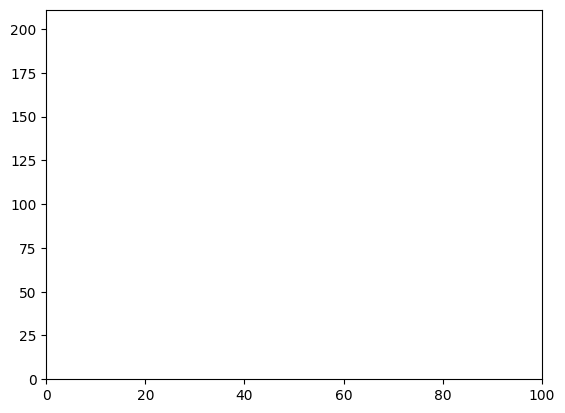

In [ ]:
# fig = plt.figure()
# ax = plt.axes(projection='3d')
fig, ax = plt.subplots()
# scat = ax.scatter(parts[0, 0], parts[0, 1], parts[0, 2], edgecolors='black')
scat = ax.scatter(parts[0, 0], parts[0, 2], edgecolors='black', s=2)
ax.set(xlim=[0, LENGTH], ylim = [0, np.max(parts[:, 2])])

def update(frame):
    surface_x = parts[:100*frame, 0]
    surface_y = parts[:100*frame, 1]
    surface_z = parts[:100*frame, 2]

    # Update scatter plot
    # data = np.stack([surface_x, surface_y, surface_z], axis=1)
    data = np.stack([surface_x, surface_z], axis = 1)
    scat.set_offsets(data)

    return scat

ani = animation.FuncAnimation(fig=fig, func=update, frames=TIME//100, interval=45)
ani

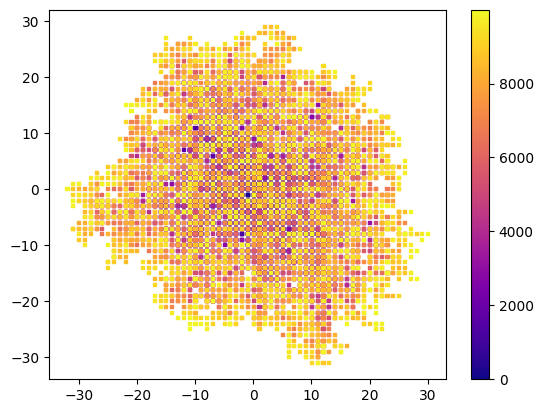

In [248]:
def eden_model(time):
    """
    Simulates (2+1)D Ballistic Deposition on a 2D lattice

    Args:
        length (int): number of lattice points in one dimension
        width (int): number of lattice points in one dimension
        time (int): number of steps to simulate ballistic deposition for

    Returns:
        particles (array of 3-tuples): positions and heights of particles added to surface at each time step
    """
    particles = np.empty((time, 2))
    particles[0] = [0, 0]
    boundary = [(0, 1), (0, -1), (-1, 0), (1, 0)]

    for t in range(time):
        point = boundary.pop(np.random.randint(0, len(boundary)))
        particles[t] = point
        add_boundary(point, boundary)
    
    return particles

def add_boundary(point, boundary):
    if (point[0]-1, point[1]) not in boundary:
        boundary.append((point[0]-1, point[1]))
    if (point[0]+1, point[1]) not in boundary:
        boundary.append((point[0]+1, point[1]))
    if (point[0], point[1]-1) not in boundary:
        boundary.append((point[0], point[1]-1))
    if (point[0], point[1]+1) not in boundary:
        boundary.append((point[0], point[1]+1))

TIME = 10000

eden_surface = eden_model(TIME)
plt.scatter(eden_surface[:, 0], eden_surface[:, 1], c=range(TIME), cmap='plasma', s=5, marker='s')
plt.colorbar()

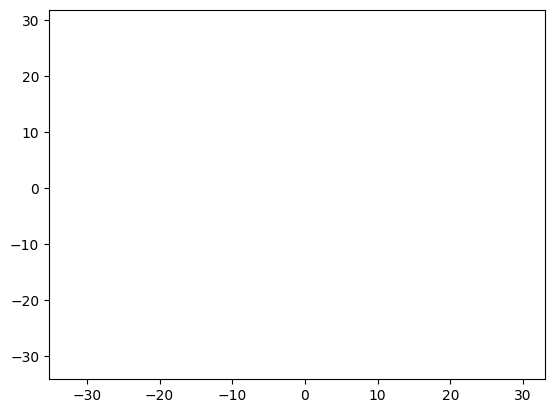

In [ ]:
fig, ax = plt.subplots()
scat = ax.scatter(eden_surface[0, 0], eden_surface[0, 1], edgecolors='black', s=5)
ax.set(xlim=[1.1 * np.min(eden_surface[:, 0]), 1.1 * np.max(eden_surface[:, 0])], 
       ylim=[1.1 * np.min(eden_surface[:, 1]), 1.1 * np.max(np.max(eden_surface[:, 1]))])

def update(frame):
    eden_x = eden_surface[:100*frame, 0]
    eden_y = eden_surface[:100*frame, 1]

    # Update scatter plot
    # data = np.stack([surface_x, surface_y, surface_z], axis=1)
    data = np.stack([eden_x, eden_y], axis = 1)
    scat.set_offsets(data)

    return scat

ani = animation.FuncAnimation(fig=fig, func=update, frames=TIME//100, interval=45)
ani